Dataset grid successfully saved as 'dataset-cover.jpg'!


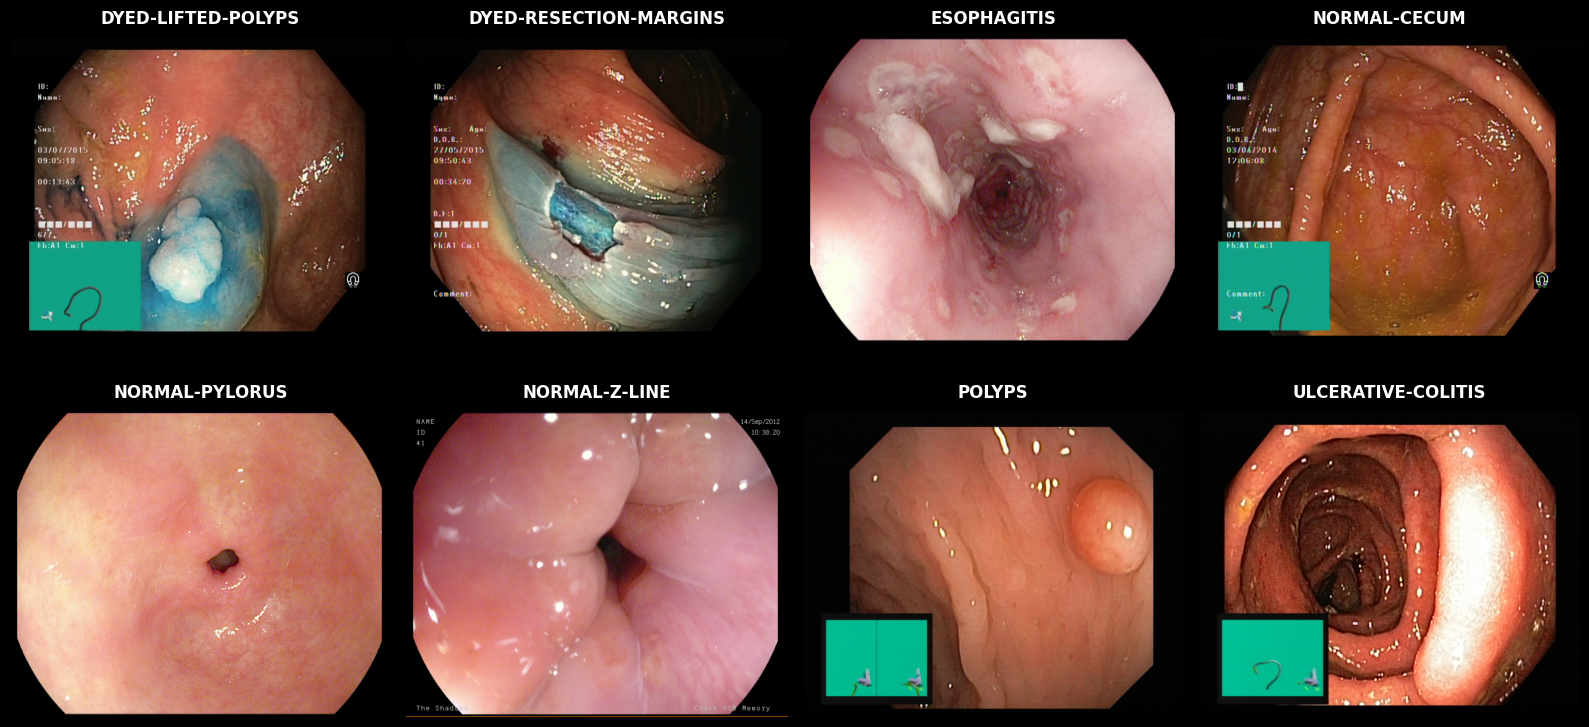

In [1]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Set this to the path where your 'kvasir-dataset' folder is located
dataset_dir = "kvasir-dataset"

# The 8 classes based on your folder structure
classes = [
    "dyed-lifted-polyps",
    "dyed-resection-margins",
    "esophagitis",
    "normal-cecum",
    "normal-pylorus",
    "normal-z-line",
    "polyps",
    "ulcerative-colitis"
]

# Create a figure with a 2x4 grid, a black background, and a specific size
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.patch.set_facecolor('black')
axes = axes.flatten()

for i, cls in enumerate(classes):
    class_path = os.path.join(dataset_dir, cls)
    
    # Check if the folder exists
    if os.path.exists(class_path):
        # Get a list of image files in the directory
        images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        
        if images:
            # Open the first image found in the folder
            img_path = os.path.join(class_path, images[0])
            img = Image.open(img_path)
            
            # Display the image
            axes[i].imshow(img)
            
            # Add the folder name as a label (white text to contrast with black background)
            axes[i].set_title(cls.upper(), color='white', fontsize=12, fontweight='bold', pad=10)
        else:
            axes[i].set_title(f"No Images\n{cls}", color='red', fontsize=12)
    else:
        axes[i].set_title(f"Missing Folder\n{cls}", color='red', fontsize=12)
        
    # Hide the axes (ticks and borders) for a cleaner look
    axes[i].axis('off')

# Adjust layout so labels don't overlap
plt.tight_layout()

# Save the generated grid to a file
output_filename = "dataset-cover.jpg"
plt.savefig(output_filename, dpi=300, bbox_inches='tight', facecolor='black')
print(f"Dataset grid successfully saved as '{output_filename}'!")

# Show the plot window
plt.show()